# Problems: Kernel Density Estimation

**Problem 1.** Suppose the data are `[1, 1.75, 2, 3, 3.25, 4]`.

- a. Sketch the empirical cumulative distribution function.
- b. Sketch the uniform kernel density estimator for a bandwidth of `h = 0.2`
- c. Compute the Silverman bandwidth for the uniform kernel using `h = 1.84 * SD * n**(-0.2)`.
- d. Sketch the uniform kernel density estimator for the Silverman bandwidth.
- e. How are b and d similar or different?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

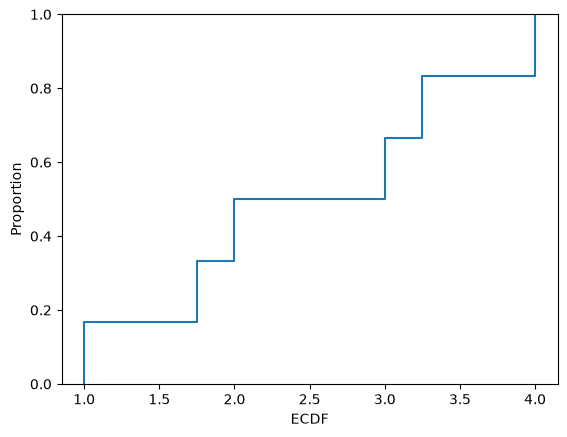

In [2]:
# a. the empirical cumulative distribution function
data = [1, 1.75, 2,3,3.25,4]

sns.ecdfplot(data)
plt.xlabel("ECDF")
plt.show()


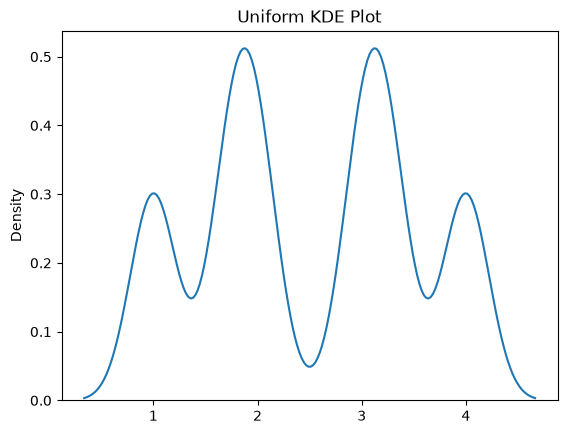

In [10]:
#sketch the uniform KDE for h=0.2
h=0.2
sns.kdeplot(data, bw_method=.2)
plt.title('Uniform KDE Plot')
plt.show()

In [5]:
#compute the silverman bandwidth using  `h = 1.84 * SD * n**(-0.2)`.
SD=np.std(data, ddof=1)
n=len(data)
h = 1.84 * SD * n**(-0.2)
print(f'Silverman bandwidth: {h:.3f}')


Silverman bandwidth: 1.423


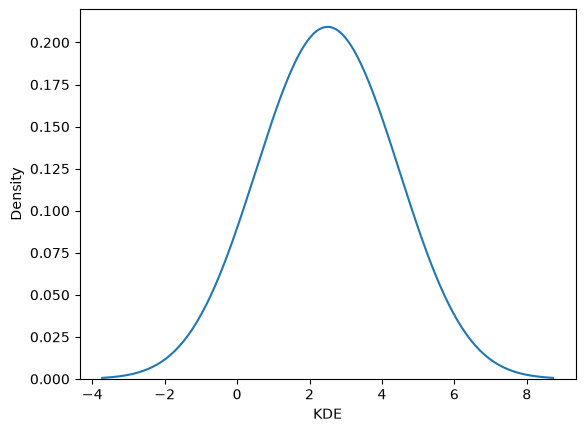

In [ ]:
#sketch the uniform kde for the silverman bandwidrh
sns.kdeplot(data, bw_method=h)
plt.xlabel('KDE')
plt.show()

How are b and d similar or different?
- the difference between b and d is the bandwidth—howmuch smoothing occurs in kernel density estimate. d is more smoother than b because of higher bandwidth.


**Problem 2.** Suppose the data `X = [-1, -0.5, 0, 0.5, 1]` were drawn from a standard Normal distribution.

- a. Using the uniform kernel with `h = 0.6`, compute the realized KDE at `x = 0`, `f_hat_h(0)`, directly from these five numbers.
- b. Now compute `E[f_hat_h(0)]` at the same `h = 0.6`.
- c. Calculate the true density at `x=0`, using the Normal distribution.
- d. Are b and c equal? What does this mean about bias? (Keep in mind, truly proving anything about bias would require us to compare `E[f_hat_h]` to the Normal distribution for all x; calculating this at one point is only an indication of what is going on that you can extrapolate from.)
- e. Recompute `E[f_hat_h(0)]` from (b) at a much smaller bandwidth, `h = 0.1`. What happens to the gap between `E[f_hat_h(0)]` and `f(0)` as `h` shrinks?
- f. Is `f_hat_h` a consistent estimator? Explain your reasoning.
- g. What are the main considerations in choosing a bandwidth value `h`?

In [ ]:
##a
X = np.array([-1, -0.5, 0, 0.5, 1])
h = 0.6
x = 0
n = len(X)
def uniform_kernel(u):
    return 0.5 if abs(u) <= 1 else 0
f_hat = sum(uniform_kernel((x - xi) / h) for xi in X) / (n * h)

print("KDE at x = 0:", f_hat)

KDE at x = 0: 0.5


In [ ]:
 #b. Now compute `E[f_hat_h(0)]` at the same `h = 0.6`.
contributions = np.array([
    uniform_kernel((x - xi) / h) / h
    for xi in X
])
E_f_hat = np.mean(contributions)

print("E[f_hat_h(0)] =", E_f_hat)


E[f_hat_h(0)] = 0.5


In [17]:
#c. Calculate the true density at `x=0`, using the Normal distribution.
from scipy.stats import norm
mu = np.mean(X)
sigma = np.std(X, ddof=0)

true_density = norm.pdf(0, loc=mu, scale=sigma)
print(f'Density: {true_density:.3f}')


Density: 0.564


#d. Are b and c equal? What does this mean about bias? (Keep in mind, truly proving anything about bias would require us to compare `E[f_hat_h]` to the Normal distribution for all x; calculating this at one point is only an indication of what is going on that you can extrapolate from.)
- No, b and c are not the same. Expected kde at x=0 is 0.5 whereas normal density distribution is 0.564. 
- the bias at x=0 is:
        - `Bias(h_hat_h(0)) = E(f_hat_h) - f(0) = 0.5-0.564 = -0.064`
        
the negative value indicate that kde underestimate the true density at x=0. 


In [ ]:
#e  Recompute `E[f_hat_h(0)]` from (b) at a much smaller bandwidth, `h = 0.1`. What happens to the gap between `E[f_hat_h(0)]` and `f(0)` as `h` shrinks?

h=0.1
x=0

def uniform_kernel(u):
    return 0.5 if abs(u) <= 1 else 0
n=len(X)

E_f_hat = np.mean([
    uniform_kernel((x - xi) / h) / h
    for xi in X
])

print("E[f_hat_h(0)] =", E_f_hat)

E[f_hat_h(0)] = 1.0


f. Is `f_hat_h` a consistent estimator? Explain your reasoning.
- Yes the kde of `f_hhat_h` can be a consistent estimator under certain condition such as when h approaches 0 or when nh——>infinity slowly. 


 g. What are the main considerations in choosing a bandwidth value `h`?

 - the main considerations in choosing a bandwidth value is balancing between bias and variance. small bandwidth h has less smoothing, lower bias and higher variance whereas large bandwidth is smooth, higher bias and low variance.

**Problem 3.** Suppose the data are `X = [5, 7, 7, 8, 10]`, and fix the bandwidth at `h = 1.5` for both kernels below.

- a. Compute the uniform-kernel KDE, `f_hat_h(x)`, at `x = 6.0`, `x = 6.5`, `x = 7.0`, `x = 8.0`, and `x = 8.5`.
- b. Compute the Gaussian-kernel KDE at the same five values of `x`, using the same `h = 1.5`.
- c. Your part (a) values should jump abruptly between some of these five points, while your part (b) values should change smoothly. Identify where the biggest jump in (a) happens, and explain in terms of the two kernel *shapes* -- not just "one is smoother" -- why that jump exists in the uniform case but not the Gaussian case.
- d. Why might you prefer one kernel over the other in practice?


In [19]:


#a. Compute the uniform-kernel KDE, `f_hat_h(x)`, at `x = 6.0`, `x = 6.5`, `x = 7.0`, `x = 8.0`, and `x = 8.5`.
X= np.array([5, 7, 7, 8, 10])
h=0.6

def uniform_kernel(u):
    return 0.5 if abs(u) <= 1 else 0

def kde(x):
    return sum(uniform_kernel((x - xi) / h) for xi in X) / (len(X) * h)

points = [6.0, 6.5, 7.0, 8.0, 8.5]

for x in points:
    print(f"x = {x:.1f}, KDE = {kde(x):.4f}")


x = 6.0, KDE = 0.0000
x = 6.5, KDE = 0.3333
x = 7.0, KDE = 0.3333
x = 8.0, KDE = 0.1667
x = 8.5, KDE = 0.1667


In [21]:
#b. Compute the Gaussian-kernel KDE at the same five values of `x`, using the same `h = 1.5`.
h=1.5
def gaussian_kernel(u):
    return (1 / np.sqrt(2 * np.pi)) * np.exp(-0.5 * u**2)

def kde(x):
    u = (x - X) / h
    return np.sum(gaussian_kernel(u)) / (len(X) * h)

points = [6.0, 6.5, 7.0, 8.0, 8.5]

for x in points:
    print(f"x = {x:.1f}, KDE = {kde(x):.4f}")

x = 6.0, KDE = 0.1512
x = 6.5, KDE = 0.1687
x = 7.0, KDE = 0.1780
x = 8.0, KDE = 0.1674
x = 8.5, KDE = 0.1506


#c. our part (a) values should jump abruptly between some of these five points, while your part (b) values should change smoothly. Identify where the biggest jump in (a) happens, and explain in terms of the two kernel *shapes* -- not just "one is smoother" -- why that jump exists in the uniform case but not the Gaussian case.
- In part a, the value jumps between when x=6.0 and x=6.5 because two data points enter at the same time where X=[5,7,7...] whereas in the Gaussian case, it changes smoothly. 

#d. Why might you prefer one kernel over the other in practice?
- Gaussian might be better in practice because it's smooth density estimator and that captures the overall data without a suden jump. 

**Problem 4.** Load `./data/heart_failure_clinical_records_dataset.csv`.

- a. Plot a
-  kernel density estimate of `ejection_fraction`.
- b. Use Pandas' `df.sample(frac=1.0, replace=True)` to resample the data 15 times with replacement, plotting the kernel density estimtes for each sample.
- c. For what values of `ejection_fraction` is the original plot reliable? For which values is there noticeable variation in your plots of the resampled data?

In [23]:
df = pd.read_csv('./data/heart_failure_clinical_records_dataset.csv')
df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


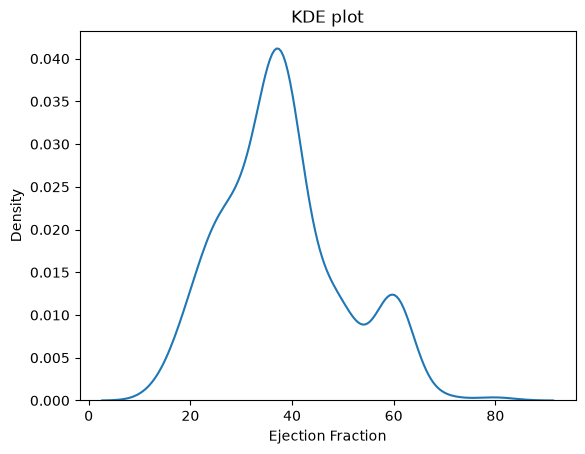

In [26]:
sns.kdeplot(df['ejection_fraction'])
plt.title('KDE plot')
plt.xlabel('Ejection Fraction')
plt.show()

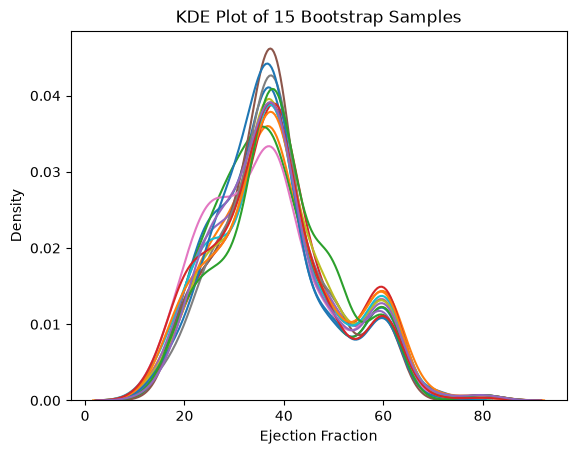

In [31]:
#b 

R= 15
for i in range(R):
    sample=df.sample(frac=1.0, replace=True)
    sns.kdeplot(sample['ejection_fraction'])
    plt.xlabel('Ejection Fraction')
    plt.title('KDE Plot of 15 Bootstrap Samples')

    

#c. For what values of `ejection_fraction` is the original plot reliable? For which values is there noticeable variation in your plots of the resampled data?
- The values of `ejection_fraction` where 15 resampled curves overlap the original kde plot which suggests that the estimated desnity is relatively stable under resampling. 